# Toxoplasma gondii: combining US (NHANES) with European data

**Question:** does adding European people to the US training data raise the score for US people?

**European datasets with participant-level Toxoplasma results (public, CC BY):**

| dataset | people tested | Toxoplasma result | questions |
|---|---|---|---|
| Czech/Slovak online survey (Flegr lab; Epidemiol Infect 2017), Figshare 1585139 | 1,371 | earlier serology test (self-reported result) | cats, cat bites/scratches, dogs, raw meat, garden soil, unwashed vegetables, water, sexual risk, residence |
| French blood donors 2019, Zenodo 18330122 | 1,995 | Evolis IgG (positive ≥ 10 IU/mL) | age group, sex, region |

Also checked: other Flegr-lab datasets (health and personality outcomes, not exposures), a Rennes IgA dataset (diagnostic),
the Achtziger Zurich study (119 people). UK Biobank and the Dutch PIENTER surveys have Toxoplasma serology but need an application.

**Fair test:** every model is scored on the same 1,002 NHANES 2013-2014 test people used since the first notebook.

In [1]:
import os, sys, warnings
if os.path.basename(os.getcwd()) == 'research_r':
    os.chdir('..')
sys.path.insert(0, 'scripts')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import europe_datasets as eu
import eval_external as ev
import combine_us_europe as cue

INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
BLUE, ORANGE = '#2a78d6', '#eb6834'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'text.color': INK,
    'font.size': 10, 'legend.frameon': False, 'figure.dpi': 110,
})

## 1. Each European dataset on its own (5-fold CV × 20 repeats)

In [2]:
rows = []
for name, f in [('Czech/Slovak', eu.czech_slovak), ('France donors', eu.france_donors)]:
    X, y = f()
    for m in ev.MODELS:
        a = ev.run(name, X, y, m)[2]
        rows.append({'dataset': name, 'people': len(y), 'positive %': round(100 * y.mean(), 1), 'model': m, 'CV AUC': a.mean()})
own = pd.DataFrame(rows)
display(own.pivot_table(index=['dataset', 'people', 'positive %'], columns='model', values='CV AUC').round(3))

,,model,LogReg,RandomForest,XGBoost
dataset,people,positive %,,,
Czech/Slovak,1371,26.8,0.650,0.656,0.668
France donors,1995,50.5,0.747,0.733,0.746


## 2. Does European data help predict US people?

,training data,training people,"US test AUC (1,002 NHANES people)",sd over 5 seeds
0,US 2009-14 only,13647,0.7178,0.0006
1,+ NHANES III (US),29171,0.7156,0.0008
2,+ Europe (Czech/Slovak + France),17013,0.7185,0.0004
3,+ NHANES III + Europe (everything),32537,0.7152,0.0004


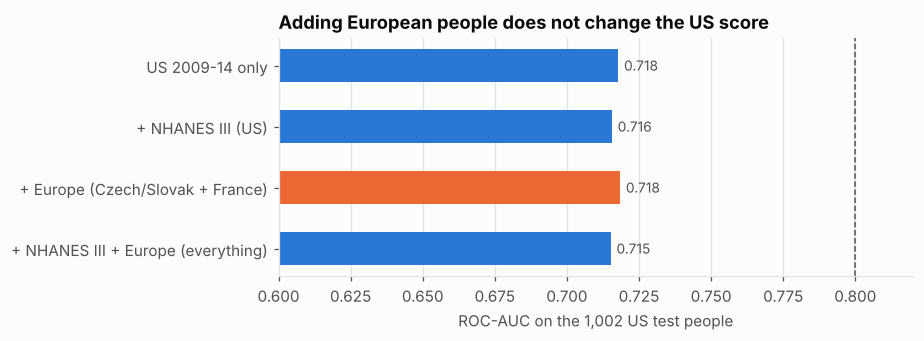

In [3]:
res, within, pooled = cue.main()
display(res.round(4))
fig, ax = plt.subplots(figsize=(8.5, 3.2))
r = res.iloc[::-1]
ax.barh(r['training data'], r['US test AUC (1,002 NHANES people)'], color=[BLUE, ORANGE, BLUE, BLUE], height=0.55)
for yv, v in enumerate(r['US test AUC (1,002 NHANES people)']):
    ax.text(v + 0.002, yv, f'{v:.3f}', va='center', fontsize=9, color=INK_2)
ax.axvline(0.8, color=INK_2, ls='--', lw=1)
ax.set_xlim(0.6, 0.82)
ax.set_xlabel('ROC-AUC on the 1,002 US test people')
ax.set_title('Adding European people does not change the US score')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

## 3. One model for everyone: pooled score vs. score inside each population

In [4]:
print(f'Pooled 5-fold CV AUC over all {int(within.people.sum()):,} people, all countries mixed: {pooled:.3f}')
display(within.round(3))

Pooled 5-fold CV AUC over all 33,539 people, all countries mixed: 0.743


,people,positive %,AUC within this dataset
dataset,,,
Czech/Slovak,1371.0,26.8,0.639
France donors,1995.0,50.5,0.749
US NHANES 2009-14,14649.0,17.0,0.745
US NHANES III 1988-94,15524.0,27.5,0.700


## What this means
- **Europe does not lift the US score.** Training with the 3,366 European people gives the same US test AUC as US data alone
  (about 0.72 for this XGBoost; the tuned final model in `toxo_max_score.ipynb` is 0.73 test / 0.74 CV). Adding NHANES III does not help either.
- **Why:** the European datasets share only age and sex with NHANES 2009-2014. Their useful questions (cat bites, soil, raw meat)
  do not exist for the US people, so the model cannot use them when it predicts a US person.
- **The European data are not stronger anyway:** Czech/Slovak 0.64-0.67 even with cat-injury, soil and raw-meat questions;
  France 0.75 with only age, sex and region (France has a steeper age gradient and 50% prevalence).
- **A pooled "combined" AUC is not a fair headline.** Mixing countries with very different prevalence (17% US vs 50% France) can make one
  number look better than any single population; here the pooled 0.743 equals the US-only score, and every within-population score stays below 0.75.
- **Conclusion for the paper:** across US and European public data, Toxoplasma prediction from questionnaire and demographic data sits at 0.64-0.75.
  0.8 was only reached in high-exposure settings (Indonesia, China) with direct questions on cats, undercooked meat and unboiled water.